# AutoMetrics — Brand Price Analysis & Comparison

## Research Question
How do vehicle prices differ across car brands, and do those
differences remain when comparing similar types of vehicles?

Our goal is to compare vehicle prices across brands and investigate
how body type, performance, and safety features relate to pricing.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

#Load our group's cleaned vehicle dataset

#Locate the cleaned dataset from either notebook or project folder
data_path = Path("../data/processed/cars_dataset_cleaned.xlsx")

if not data_path.exists():
    data_path = Path("data/processed/cars_dataset_cleaned.xlsx")

if not data_path.exists():
    raise FileNotFoundError("Cleaned dataset not found.")

df = pd.read_excel(data_path)

#Confirm that the data loaded correctly
print("Dataset shape:", df.shape)
print("\nAvailable brands:")
print(sorted(df["make"].unique()))

print("\nVehicle body types:")
print(sorted(df["body_type"].unique()))

df.head()


Dataset shape: (100000, 26)

Available brands:
['Audi', 'BMW', 'Chevrolet', 'Ford', 'Honda', 'Hyundai', 'Kia', 'Lexus', 'Mazda', 'Mercedes-Benz', 'Nissan', 'Toyota', 'Volkswagen']

Vehicle body types:
['Convertible', 'Coupe', 'Crossover', 'Hatchback', 'Minivan', 'Pickup', 'SUV', 'Sedan', 'Van']


,vehicle_id,make,model,model_variant,model_year,vehicle_year,vehicle_age,body_type,brand_reputation_score,brand_reliability_score,...,torque_to_weight_ratio,handling_score,acceleration_score,braking_score,performance_score,reliability_score,original_price,msrp,total_feature_count,safety_feature_count
0,V00000001,BMW,i4,i4 RS,2020,2020,6,Sedan,88,78,...,311.439026,35.2,71.1,94.9,65.4,72.3,54950.99,56204.07,31,12
1,V00000002,Chevrolet,Equinox,Equinox SE,2016,2016,10,SUV,78,76,...,155.944885,35.9,77.3,57.8,66.2,52.7,24526.91,25741.61,21,9
2,V00000003,Kia,Sportage,Sportage M Sport,2024,2024,2,SUV,83,86,...,163.426372,41.1,78.3,86.0,65.9,78.2,26483.37,27482.64,18,8
3,V00000004,Hyundai,Ioniq 5,Ioniq 5 Sport,2015,2015,11,SUV,84,87,...,162.831227,40.3,60.7,73.3,62.4,71.6,53048.43,53061.91,37,15
4,V00000005,Honda,Accord,Accord GT,2022,2022,4,Sedan,90,92,...,262.573882,40.8,77.5,68.2,62.0,92.3,29120.61,29362.80,19,7



## Dataset and Preparation

This analysis uses the AutoMetrics cleaned vehicle dataset,
which contains 100,000 vehicle records and 26 columns.

The dataset was originally obtained from Kaggle and prepared
by our group before this analysis.

During cleaning:
- Duplicate records were checked.
- Text values were standardized.
- Missing values were preserved rather than filled with estimates.
- The cleaned dataset was saved separately from the original.

There are 1,000 missing original prices and 2,000 missing MSRP
values. Price comparisons use available, non-missing prices.

We use `original_price` for the main price comparisons to stay
consistent with the group's initial exploratory analysis. The
clearly labeled supplementary brand chart uses `msrp`.

The dataset's currency and collection methodology have not
been independently verified, so prices are reported in dataset
units.


## 1. Brand Price Comparison

We first compare vehicle prices across all 13 brands in the
dataset to see which brands have higher or lower typical prices.

We use the median price because it is less affected by unusually
expensive vehicles than the mean. We also include the number
of vehicles for each brand to understand the sample sizes.

In [2]:

#Calculate price statistics for each car brand
brand_prices = df.groupby("make")["original_price"].agg(
    vehicle_count="count",
    median_price="median",
    mean_price="mean"
)

#Sort brands from highest to lowest median price
brand_prices = brand_prices.sort_values(
    by="median_price",
    ascending=False
)

#Display the results rounded to two decimal places
brand_prices.round(2)


,vehicle_count,median_price,mean_price
make,,,
Mercedes-Benz,5984,64564.95,75326.90
BMW,5332,62045.96,66070.38
Audi,4290,52400.92,63687.90
Lexus,3797,47193.37,57273.09
Chevrolet,9842,33479.09,38351.57
Volkswagen,7827,33461.39,33548.15
Ford,12438,32427.20,31753.27
Toyota,12959,31094.55,37187.82
Kia,6686,30293.39,31766.61


### Visualization 1: Median Vehicle Price by Brand

This chart compares the median original price across all 13 brands.
We use median prices to reduce the influence of unusually expensive
vehicles and show sample sizes to provide context for each comparison.

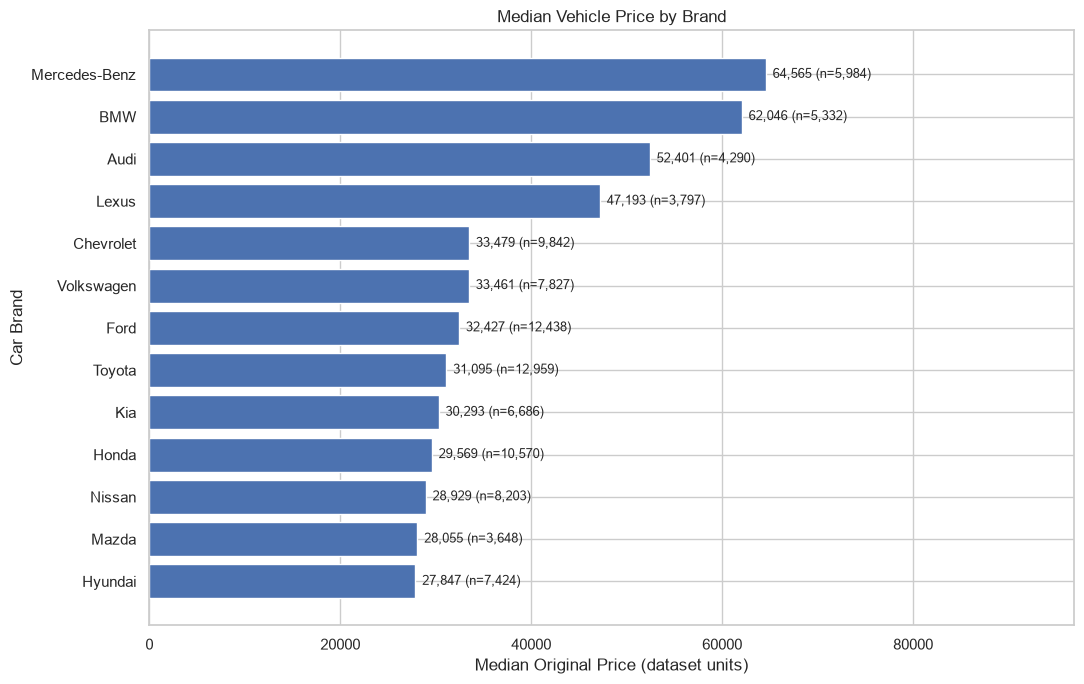

In [3]:

#Sort brands from lowest to highest median price
plot_data = brand_prices.sort_values("median_price")

#Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data.index,
    plot_data["median_price"]
)

#Show median price and sample size for each brand
labels = [
    f"{price:,.0f} (n={count:,})"
    for price, count in zip(
        plot_data["median_price"],
        plot_data["vehicle_count"]
    )
]

ax.bar_label(bars, labels=labels, padding=5, fontsize=9)

#Add chart title and axis labels
ax.set_title("Median Vehicle Price by Brand")
ax.set_xlabel("Median Original Price (dataset units)")
ax.set_ylabel("Car Brand")

#Start the price axis at zero and leave room for labels
ax.set_xlim(0, plot_data["median_price"].max() * 1.5)

plt.tight_layout()
plt.show()



### Findings: Brand Price Comparison

Mercedes-Benz has the highest median original price at approximately
64,565, followed by BMW at 62,046 and Audi at 52,401. Hyundai has
the lowest median price at approximately 27,847.

Mercedes-Benz's median price is more than twice Hyundai's,
showing a noticeable difference in typical prices across brands.

These comparisons use available original prices. Of the 100,000
vehicle records, 99,000 have a known original price. Missing prices
were excluded from the calculations rather than filled with estimates.

However, these comparisons include all vehicle body types. Some
brands may have more SUVs, luxury models, or performance vehicles
than others, which could contribute to their higher prices.

Therefore, we cannot conclude that brand identity alone causes the
price differences. Comparing vehicles within the same body types
provides a more meaningful follow-up analysis.


### Supplement: Median MSRP by Brand (Luxury vs. Mainstream)

This supplementary chart uses actual `msrp` values from the same cleaned dataset. The earlier comparisons continue to use `original_price`. Missing MSRP values are skipped only for this calculation; no prices are filled and no dataset records are changed. The table includes the number of available MSRP values per brand.

**The classification is manually defined:** Mercedes-Benz, BMW, Audi, and Lexus are labeled luxury, following the original visualization script. All remaining brands are labeled mainstream for this chart only. These are analyst-selected categories, not a dataset field or a verified classification of every model. Colors describe these groups; they do not explain why prices differ. Currency is unverified, so prices are shown in dataset units.

,count,median
make,,
Hyundai,7375,28567.25
Mazda,3611,28749.10
Nissan,8116,29650.34
Honda,10506,30362.06
Kia,6637,31042.86
Toyota,12781,31904.38
Ford,12291,33253.73
Volkswagen,7734,34250.04
Chevrolet,9742,34333.05


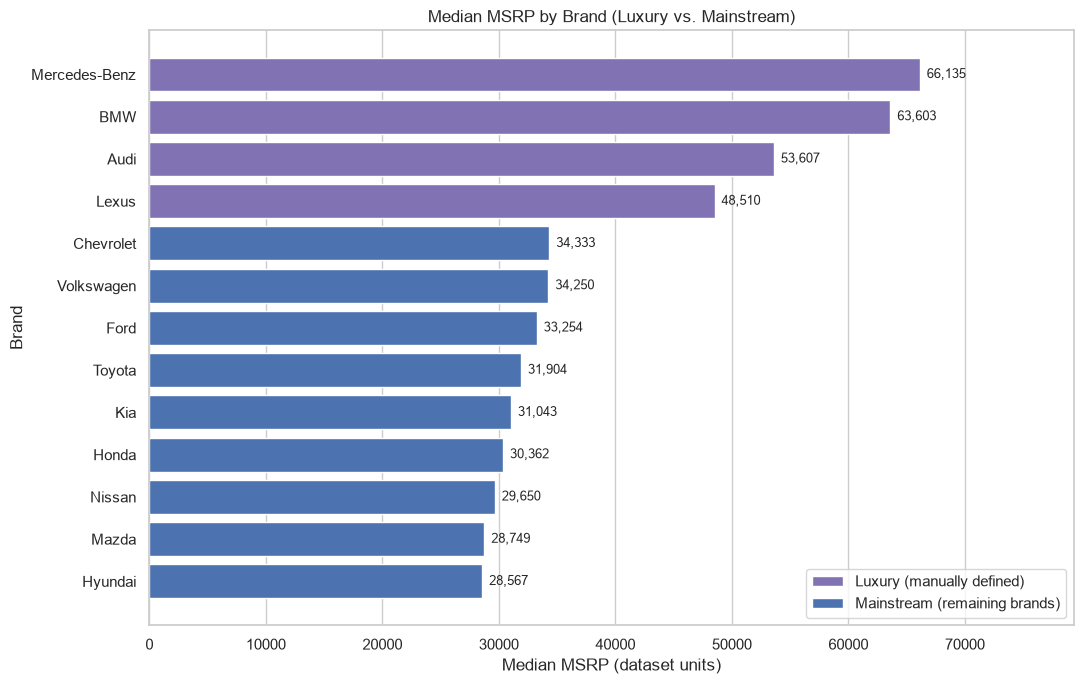

In [4]:
# Calculate medians using every available MSRP, including rows missing original_price.
msrp_by_brand = df.groupby("make")["msrp"].agg(["count", "median"])
msrp_by_brand = msrp_by_brand.sort_values("median")
display(msrp_by_brand.round(2))

# These groups are manually selected, not supplied by the dataset.
luxury_brands = ["Mercedes-Benz", "BMW", "Audi", "Lexus"]
brand_colors = []
for brand in msrp_by_brand.index:
    if brand in luxury_brands:
        brand_colors.append("#8172B3")
    else:
        brand_colors.append("#4C72B0")

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(msrp_by_brand.index, msrp_by_brand["median"], color=brand_colors)
labels = [f"{value:,.0f}" for value in msrp_by_brand["median"]]
ax.bar_label(bars, labels=labels, padding=5, fontsize=9)
# Match the legend colors to the manually defined groups.
from matplotlib.patches import Patch
legend_labels = [
    Patch(facecolor="#8172B3", label="Luxury (manually defined)"),
    Patch(facecolor="#4C72B0", label="Mainstream (remaining brands)")
]
ax.legend(handles=legend_labels, loc="lower right")
ax.set_xlim(0, msrp_by_brand["median"].max() * 1.20)
ax.ticklabel_format(style="plain", axis="x")
ax.set_title("Median MSRP by Brand (Luxury vs. Mainstream)")
ax.set_xlabel("Median MSRP (dataset units)")
ax.set_ylabel("Brand")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**MSRP findings:** Across 98,000 available MSRP values, Mercedes-Benz has the highest brand median (66,135.48), followed by BMW (63,603.10), Audi (53,606.89), and Lexus (48,510.46). Hyundai has the lowest median (28,567.25). The four manually selected luxury brands have the four highest medians in this dataset. This is a descriptive comparison: differences in the mix of models, body types, and features may also contribute. MSRP and original price are closely related, so this is not independent evidence that a brand label causes higher prices.

## 2. Brand Prices Within Vehicle Body Types

To make the comparisons more meaningful, we separate SUVs and
sedans before comparing prices across brands.

This helps us investigate whether the overall brand price
differences remain when we account for vehicle body type.

In [5]:

#Select only SUVs and sedans
selected_vehicles = df[
    df["body_type"].isin(["SUV", "Sedan"])
]

#Calculate price statistics by body type and brand
body_type_prices = selected_vehicles.groupby(
    ["body_type", "make"]
)["original_price"].agg(
    vehicle_count="count",
    median_price="median"
).reset_index()

#Display SUV comparisons
print("SUV Price Comparison")
display(
    body_type_prices[
        body_type_prices["body_type"] == "SUV"
    ].sort_values(
        "median_price", ascending=False
    ).round(2)
)

#Display sedan comparisons
print("Sedan Price Comparison")
display(
    body_type_prices[
        body_type_prices["body_type"] == "Sedan"
    ].sort_values(
        "median_price", ascending=False
    ).round(2)
)


SUV Price Comparison


,body_type,make,vehicle_count,median_price
9,SUV,Mercedes-Benz,2332,74994.74
1,SUV,BMW,1592,65261.59
7,SUV,Lexus,1556,52976.30
0,SUV,Audi,1762,50564.41
12,SUV,Volkswagen,2353,41973.98
2,SUV,Chevrolet,3908,40361.48
5,SUV,Hyundai,3733,38602.66
11,SUV,Toyota,3927,38136.47
8,SUV,Mazda,1794,34443.70
3,SUV,Ford,4928,34394.84


Sedan Price Comparison


,body_type,make,vehicle_count,median_price
22,Sedan,Mercedes-Benz,2441,82787.46
14,Sedan,BMW,2741,60418.76
13,Sedan,Audi,1671,45584.01
20,Sedan,Lexus,1050,43452.59
19,Sedan,Kia,1287,36283.50
25,Sedan,Volkswagen,2322,30163.91
17,Sedan,Honda,2390,24883.86
16,Sedan,Ford,1269,24874.76
24,Sedan,Toyota,2502,24839.47
21,Sedan,Mazda,740,24601.08


### Visualization 2: Median SUV and Sedan Prices by Brand

This chart compares median original prices for SUVs and sedans
within each brand. Separating the vehicle types allows us to
investigate whether brand pricing differences remain within
the same category.

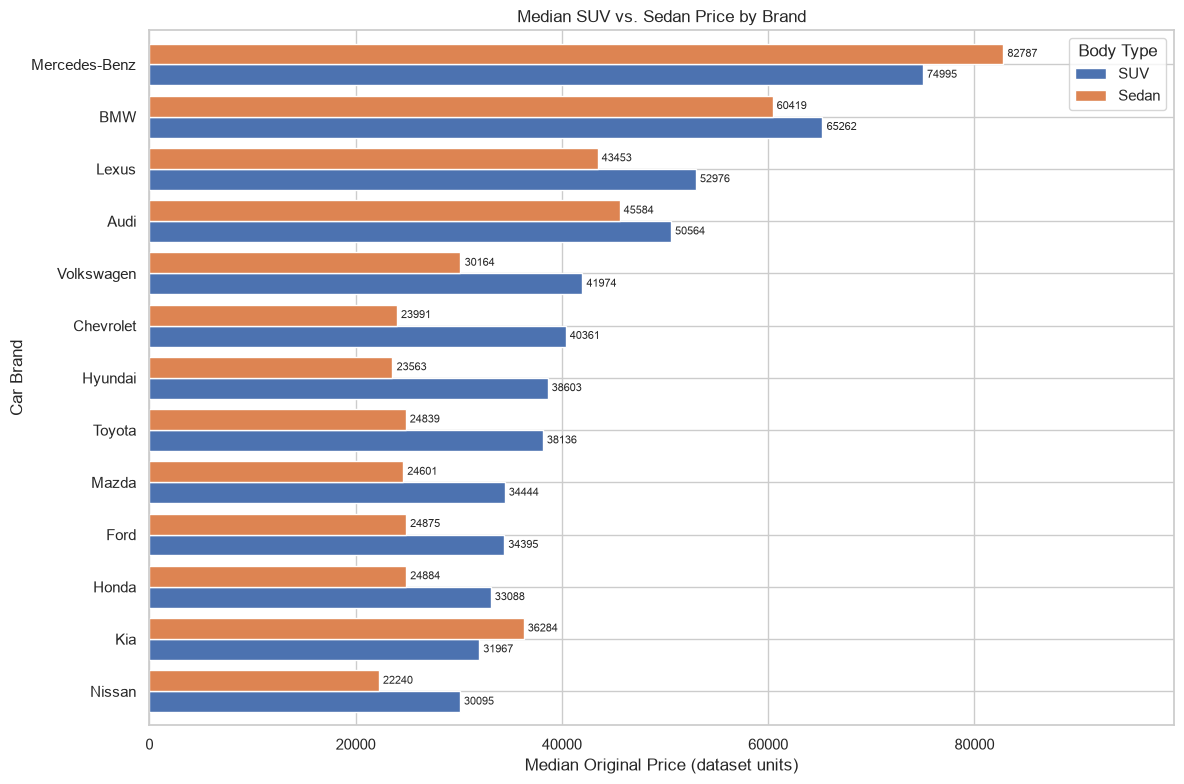

In [6]:

#Organize SUV and sedan median prices by brand
price_comparison = body_type_prices.pivot(
    index="make",
    columns="body_type",
    values="median_price"
)

#Sort brands by SUV median price
price_comparison = price_comparison.sort_values("SUV")

#Create side-by-side horizontal bars
fig, ax = plt.subplots(figsize=(12, 8))

price_comparison[["SUV", "Sedan"]].plot(
    kind="barh",
    ax=ax,
    width=0.8
)

#Add price labels to each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)

#Add title and labels
ax.set_title("Median SUV vs. Sedan Price by Brand")
ax.set_xlabel("Median Original Price (dataset units)")
ax.set_ylabel("Car Brand")
ax.legend(title="Body Type")

#Leave room for price labels
ax.set_xlim(0, price_comparison.max().max() * 1.2)

plt.tight_layout()
plt.show()



### Findings: SUV vs. Sedan Price Comparison

After separating SUVs and sedans, Mercedes-Benz still has the
highest median original price in both categories.

For SUVs, Mercedes-Benz has a median price of approximately
74,995, compared with Toyota at 38,136.

For sedans, Mercedes-Benz has a median price of approximately
82,787, compared with Toyota at 24,839.

Nissan has the lowest median price in both categories.

For most brands, SUVs have higher median prices than sedans.
However, Mercedes-Benz and Kia show the opposite pattern.

These results suggest that differences in vehicle body type
alone do not account for the observed brand-price gaps.

The comparisons exclude records with missing original prices.
Vehicles within the same body type may still differ in model,
age, performance, and equipment.

Therefore, the findings show associations rather than proving
that brand identity causes a particular vehicle price.


## 3. Performance and Safety Features vs. Price

This analysis examines whether original vehicle prices are
associated with performance scores and safety feature counts.

We calculate correlations for the overall dataset, SUVs,
and sedans to see whether these relationships differ by
vehicle category.

In [7]:

#Columns used for the correlation analysis
columns = [
    "original_price",
    "performance_score",
    "safety_feature_count"
]

#Compare correlations across vehicle groups
groups = {
    "All Vehicles": df,
    "SUVs": df[df["body_type"] == "SUV"],
    "Sedans": df[df["body_type"] == "Sedan"]
}

for group_name, group_data in groups.items():
    correlations = group_data[columns].corr()

    print(f"\n{group_name} (n={group_data['original_price'].notna().sum():,})")

    print(
        correlations["original_price"]
        .drop("original_price")
        .round(3)
    )



All Vehicles (n=99,000)
performance_score       0.358
safety_feature_count    0.488
Name: original_price, dtype: float64

SUVs (n=36,161)
performance_score       0.269
safety_feature_count    0.533
Name: original_price, dtype: float64

Sedans (n=22,479)
performance_score       0.380
safety_feature_count    0.614
Name: original_price, dtype: float64


### Visualization 3: Correlation of Price with Performance and Safety Features

This chart compares Pearson correlation coefficients for performance
score and safety feature count across all vehicles, SUVs, and sedans.

It helps identify which variables have stronger linear associations
with price and whether these relationships change by body type.

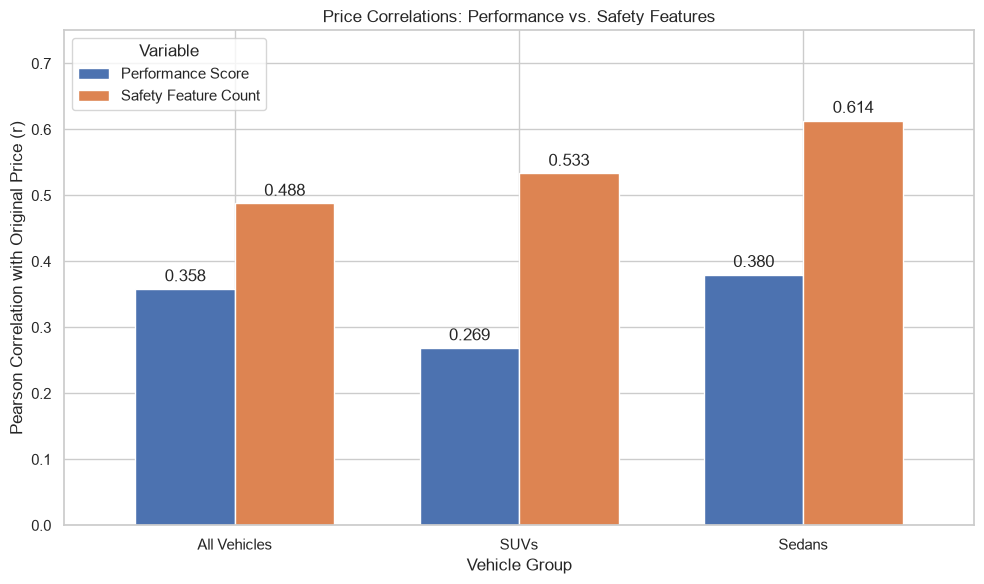

In [8]:

#Calculate correlations for each vehicle group
correlation_results = []

for group_name, group_data in groups.items():
    correlation_results.append({
        "Vehicle Group": group_name,
        "Performance Score": group_data["original_price"].corr(
            group_data["performance_score"]
        ),
        "Safety Feature Count": group_data["original_price"].corr(
            group_data["safety_feature_count"]
        )
    })

#Create a table of correlation results
correlation_df = pd.DataFrame(
    correlation_results
).set_index("Vehicle Group")

#Create a grouped bar chart
fig, ax = plt.subplots(figsize=(10, 6))

correlation_df.plot(
    kind="bar",
    ax=ax,
    width=0.7
)

#Add correlation values above the bars
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)

#Add labels and formatting
ax.set_title("Price Correlations: Performance vs. Safety Features")
ax.set_ylabel("Pearson Correlation with Original Price (r)")
ax.set_xlabel("Vehicle Group")
ax.set_ylim(0, 0.75)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Variable")

plt.tight_layout()
plt.show()



### Findings: Performance and Safety Features

Both performance score and safety feature count show positive
correlations with original vehicle price.

Across the 99,000 vehicles with known original prices, safety
feature count has a stronger correlation with price (r = 0.488)
than performance score (r = 0.358).

This pattern also appears when SUVs and sedans are examined
separately. Sedans have the strongest safety feature correlation
(r = 0.614), followed by SUVs (r = 0.533).

Performance score has a weaker relationship with price,
particularly among SUVs (r = 0.269).

These results suggest that higher-priced vehicles tend to
have more listed safety features and higher performance scores.

However, correlation does not establish causation. Brand,
model, and equipment level may influence these relationships.

Additionally, safety feature count measures the number of
listed features, not actual vehicle safety performance.



## 4. Overall Conclusions and Limitations

Our analysis found noticeable differences in median original
prices across the 13 car brands in the AutoMetrics dataset.

Mercedes-Benz had the highest median price overall at
approximately 64,565 and remained the highest-priced brand
when SUVs and sedans were compared separately.

This suggests that differences in vehicle body type alone
do not account for the observed brand-price gaps.

We also found positive correlations between original price,
performance score, and safety feature count. Safety feature
count showed a stronger positive linear relationship with
price across all three vehicle groups.

### Limitations

- The analysis identifies associations, not causal relationships.
- Vehicles within the same body type may still differ in model,
  equipment, age, and performance.
- The dataset contains 100,000 vehicle records, but 1,000 have
  missing original prices. Price calculations use the 99,000
  records with available original prices.
- Missing prices were preserved rather than replaced with
  estimated values.
- Safety feature count measures listed features, not verified
  vehicle safety ratings.
- The dataset's currency and collection methodology have not
  been independently confirmed.

Overall, the findings show that vehicle prices differ by
brand and are associated with certain vehicle characteristics.
Further analysis would be needed to determine how much each
factor independently contributes to pricing.
